<a href="https://colab.research.google.com/github/lonen8188/Ai_openCV26-10/blob/master/07_02_%EC%8B%AC%EC%B8%B5%EC%8B%A0%EA%B2%BD%EB%A7%9D(%EB%94%A5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 인공 신경망에 층을 추가하여 데이터셋을 분류하면 딥! -> 심층 신경망

# 실행마다 동일한 결과를 얻기 위해 케라스에 랜덤 시드를 사용하고
# 텐서플로 연산을 결정적으로 만듭니다.
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
# 파이썬, 텐서플로, 넘파이(Numpy) 등 케라스와 연결된 주요 난수 생성기들의 시드(Seed) 값을 일괄 고정합니다.
tf.config.experimental.enable_op_determinism()
# 텐서플로 내부 연산(GPU/CPU 연산)들을 결정론적(Deterministic) 연산으로 동작하게 강제합니다.
# 난수 시드를 고정하더라도, 병렬 연산(GPU 등) 특성상 계산 순서가 미세하게 뒤바뀌어 매번 결과가 달라질 수 있습니다.
# 이 코드는 그러한 병렬 연산에 따른 미세한 오차까지 완전히 없애줍니다

from tensorflow import keras

(train_input, train_target), (
    test_input, test_target) = keras.datasets.fashion_mnist.load_data()
# 케라스 API에서 패션 MNIST 데이터 셋을 불러옴
# 훈련세트와 테스트 셋을 만듬

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
from sklearn.model_selection import train_test_split

# 이미지의 필셀 값이 0~155 범위에서 0~1사이로 변환
train_scaled = train_input / 255.0
# 28x28 크기의 2차원 배열을 만들어 784 크기의 1차원 배열로 펼침
train_scaled = train_scaled.reshape(-1, 28*28)

train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)
# 20%의 훈련세트와 검증세트로 분할

In [ ]:
print(test_input.shape, test_target.shape)

(10000, 28, 28) (10000,)


In [ ]:
print(train_scaled.shape, train_target.shape)

(48000, 784) (48000,)


In [ ]:
print(val_scaled.shape, val_target.shape)

(12000, 784) (12000,)


In [ ]:
# 인공 신경망 모델에 2개의 레이어를 추가해 보겠다
# 전에 만든 신경망 모델과 다른 점은 입력층과 출력층 사이에 밀집 층이 추가된 것
#   -> 은닉층(hidden layer)
# 은닉층에는 주황색원으로 활성화 함수가 표시되어 있다.
# 활성화 함수는 신경망 층의 선형 방정식 계산 값에 적용하는 함수이다.
# 출력층에 적용하는 활성화 함수는 종류가 제한되어 있음
#   이진분류(시그모이드함수), 다중분류(소프트맥스함수) -> 분류를 위한
# 은닉층은 활성화 함수가 자유롭다 (대표적 : 시그모이드함수, 볼 렐루 함수....)
# a*4+2*b -> b*3-5=c 라고 했을 때  b가 하는 일은 임시용 -> a*12+1=c

# 신경망도 마찬가지로 은닉층에서 선형적인 산술 계산만 수행다면 수행 역할이 없는 셈
# 선형 계산을 적당하게 비선형적으로 비틀어 줘야 함
# 그래야 다음 층의 계산과 단순히 합쳐지지 않고 나름의 역할을 할 수 있다.
# a*4+2*b -> log(b)=k -> k*3-5=c 라고 했을 때 log(b)=k 가 하는 일은?

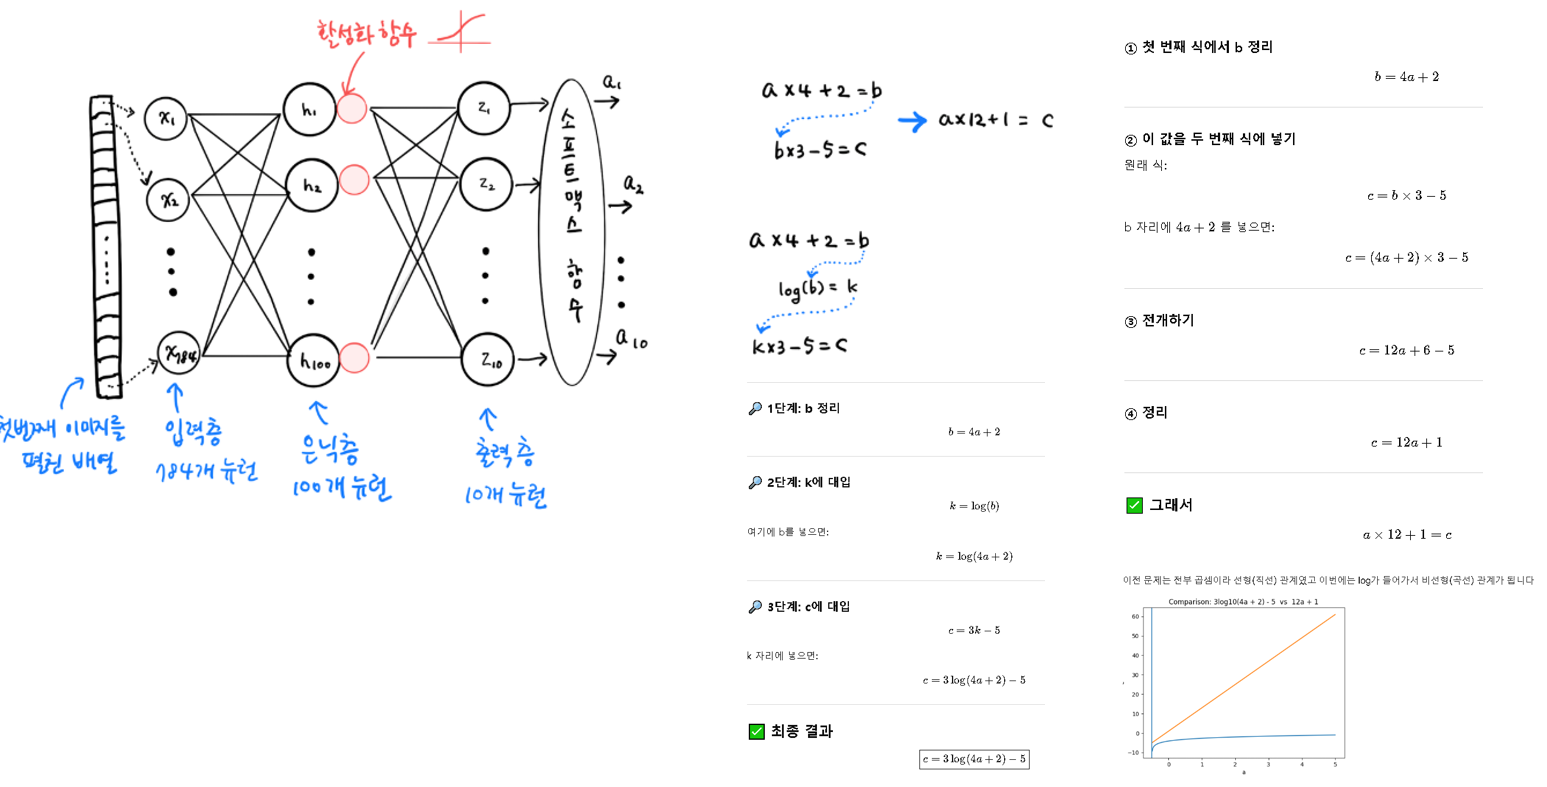

In [ ]:
# 시그모이드 활성화 함수를 사용한 은닉층과 소프트맥스 함수를
# 사용한 출력층을 케라스 Dense 클래스로 만들어 보자.
dense1 = keras.layers.Dense(100, activation='sigmoid', input_shape=(784,))
#input_shape=(784,) 입력의 크기 필수
# dense1의 목표 : 784개의 입력을 시그모이드 함수를 이용해서 100개로 만들어봐~
# 784개의 정밀한 픽셀 정보를 곧바로 10개의 클래스(옷 종류)로 줄이기보다는,
# 중간 단계에서 100개 정도의 다채로운 특징 조합(패턴, 테두리, 형태 등)으로
# 요약·압축하도록 역할을 맡긴 것입니다.

# dense1 이 은닉층이고 100개의 뉴런을 가진 밀집층, 활성화 함수를 시그모이드로 설정
# 몇개의 뉴런이 필요할 지는 경험적으로 기입
# 제약사항으로는 적어도 출력층의 뉴런보다는 많게 만들어야 한다.
# (클래스 10개에 대한 확률을 예측해야 하는데 은닉층의 뉴런이 10개 이하면 안됨)

dense2 = keras.layers.Dense(10, activation='softmax')
# dense2은 출력층으로 설정 (10개의 클래스를 분류하므로 10개의 뉴런을 둠)
# https://wikidocs.net/120089
# 활성화 함수로 소프트 맥스 함수로 지정

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# 최신 Keras 3에서는 입력 형태를 명확하게 정의하기 위해
# Input() 레이어를 가장 첫 번째 층으로 명시적으로 추가하는 방식을 권장합니다.
# model = keras.Sequential([
#     keras.Input(shape=(784,)), # 입력 크기를 명시하는 전용 레이어 추가
#     keras.layers.Dense(100, activation='relu'),
#     keras.layers.Dense(10, activation='softmax')
# ])

In [ ]:
# 심층 신경망 만들기 (순차적으로 적용하기 위한 모델)
model = keras.Sequential([dense1, dense2])

# 위에서 만든 dense1, dense2를 Sequential 클래스에 추가하여 심층(deep) 신경망을 만듬
# dense1, dense2를 리스트로 만들어 전달함
# 주의 : 뒤에가 출력층임으로 dense2를 설정
# 인공 신경망의 강력한 성능은 층을 추가하여 입력 데이터에 대해
# 연속적인 학습을 진행하는 능력 -> 2개 이상 층을 추가 가능

In [ ]:
model.summary() # 층에 대한 유용한 정보가 나옴

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 맨 첫줄에 모델의 이름, 그 다음 이 모델이 들어 있는 층이 순서대로 나옴
# 맨 처음 추가한 은닉층에서 출력층의 순서대로 나옴

# 층이름(클래스), 출력크기, 모델 파라미터 개수
# 층이름을 지정하지 않으면 케라스가 자동으로 Dense라고 이름을 붙임
# 출력크기 (None(샘플의 개수: 아직 정의되지 않음), 100)
#    -> 케라스 모델의 fit() 메서드에 훈련 데이터를 주입하면
#       이 데이터를 한번에 모두 사용하지 않고 잘게 나누어
#       여러번 걸쳐 경사 하강법 단계를 수행(미니배치 경사 하강법)
#       케라스의 기본 미니배치 크기는 32개 임

# 이 값은 fit() 메서드에서 batch_size 매개변수로 변경 가능 따라서
# 샘플 개수를 고정하지 않고 어떤 배치 크기에도 유연하게 대응할 수 있도록 None으로 설정이 최선

# 신경망 층에서 입력되거나 출력되는 배열의 첫 번째 차원을 배치 자원이라고 부름

# 출력크기 (None, 100 -> 은닉층의 뉴런 개수를 100개임으로 100개의 출력이 나옴)
#   -> 샘플마다 784개의 필셀 값이 은닉층을 통과하면서 100개의 특성으로 압축
# 마지막으로 파라미터 개수가 출력됨 784 * 100 + 100 = 78500
# 공식 : 입력개수 * 출력개수(절편) + 출력개수(절편) = 파라미터수

In [ ]:
# 두번째 층의 출력 크기 (None, 10) -> 뉴런 개수가 10개임
# 파라미터는 100 * 10 + 10 = 1010개

# 맨 아래 있는 Non-trainable params: 0 (0.00 B) 는 훈련되지 않는 파라미터
# (간혹 경사 하강법으로 훈련되지 않는 파라미터를 가진 층의 파라미터)

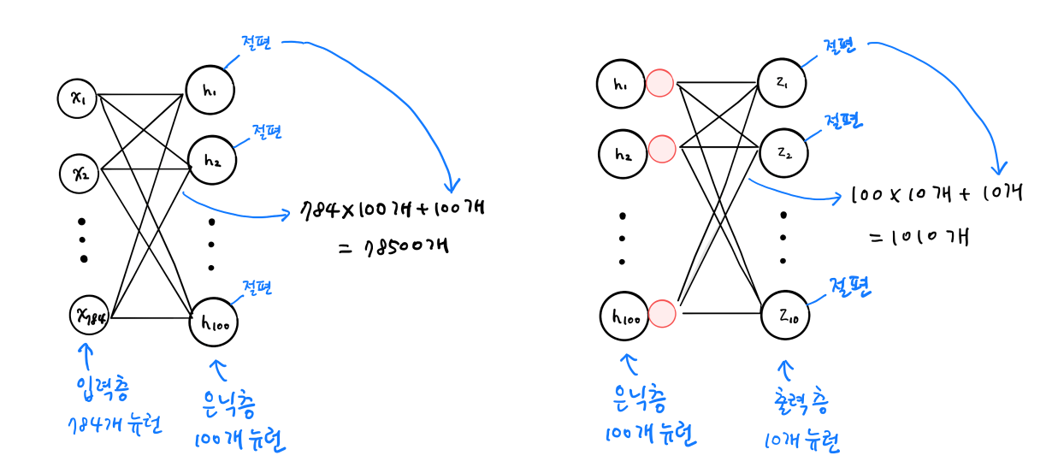

In [ ]:
# 층을 만드는 방법은 3개가 있다. 위에 처럼 변수에 넣는 방법
# 모델을 만들면서 층을 추가하는 방법 | Sequential클래스에 층을 추가하는 다른 방법
# 앞에 2개의 Dense는 따로 저장하여 쓸일이 없기 때문에
# 아래 코드처럼 Sequential 클래스의 생성자 안에서 바로 Dense 클래스의 객체를 만드는 경우가 많다.

model = keras.Sequential([                            # name='hidden' 레이어 이름 정의(영어만!)
    keras.layers.Dense(100, activation='sigmoid', input_shape=(784,), name='hidden'),
    keras.layers.Dense(10, activation='softmax', name='output')
    ], name='패션 MNIST 모델')  # 모델의 이름
model.summary()

Model: "패션 MNIST 모델"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 층(layer) 추가시 가장 편한 방법은 .add()를 사용한다. -> 메서드나 함수 활용시
model = keras.Sequential()  # 새로운 모델 생성
model.add(keras.layers.Dense(100, activation='sigmoid', input_shape=(784,)))
model.add(keras.layers.Dense(10, activation='softmax'))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 모델 훈련 시작!
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.fit(train_scaled, train_target, epochs=5)
# 처음 훈련에는 80.64% 였다가 5번의 반복을 통해서 87.81% 향상됨 / 손실율 33.52%

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8064 - loss: 0.5710
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8502 - loss: 0.4133
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8620 - loss: 0.3769
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8713 - loss: 0.3531
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8781 - loss: 0.3352


In [ ]:
# 1개의 층으로만 돌렸을 때는 정확도가 0.8458 / loss: 0.4444
# 2개의 층으로 돌렸을 경우 정확도가 87.74 %로 향상됨

# 훈련결과를 보면 훈련 세트에 대한 성능이 추가된 층이 성능을 향상시켰다는 것을 잘 알 수 있다.
model.evaluate(val_scaled, val_target) # 검증 점수 86.95% / 손실율 35.68%

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8695 - loss: 0.3568


[0.35684970021247864, 0.8694999814033508]

In [ ]:
# 초창기 인공 신경망의 은닉층에서 많이 사용된 활성화 함수는 시그모이드 함수였지만
# 단점이 오른쪽, 왼쪽 끝으로 갈수록 그래프가 누워 올바른 출력을 만드는데 신속하게 대응하지 못함.
# 특히 층이 많은 심층 신경망 일수록 그 효과가 누적되어 학습을 더 어렵게 만듬.

# 개선을 위해서 다른 종류의 활성화 함수가 제안 되었는데 바로 렐루(ReLU) 함수임
# 렐루 함수는 입력이 양수 일 경우 마치 활성화 함수가 없는 것 처럼
# 그냥 입력을 통과시키고 음수일 경우 0 으로 만듬.
# 렐루 함수는 max(0, z)와 같이 씀 -> z가 0보다 크면 z를 출력하고 0보다 작으면 0을 출력

# 렐수 함수는 특히 이미지 처리에 좋은 성능을 낸다고 함
# 은닉 층에 활성화 함수에 시그모이드 함수 대신 렐루 함수를 적용하기 전에
# 케라스에서 제공하는 편리한 층 하나를 더 알아볼 필요가 있다. -> Flatten(이미지픽셀용)
# Flatten(플래튼) : 단조롭게하다 ( 28x28 = 784가 아니라 그냥 28,28로 입력함 )
# 클래스는 배치 자원을 제외하고 나머지 입력 차원을 모두 일렬도 펼치는 역할만 함.(가중치, 절편 없음)

# 절편 : 직선이 x축과 만나는 점의 x좌표(x절편) 및 y축과 만나는 점의 y좌표(y절편)를 통틀어 이르는 말
# 하지만 플래튼 클래스를 층처럼 입력층과 은닉층 사이에 추가하기 때문에 이를 층이라고 부름
# 입력층 바로 뒤에 플래튼 층 추가

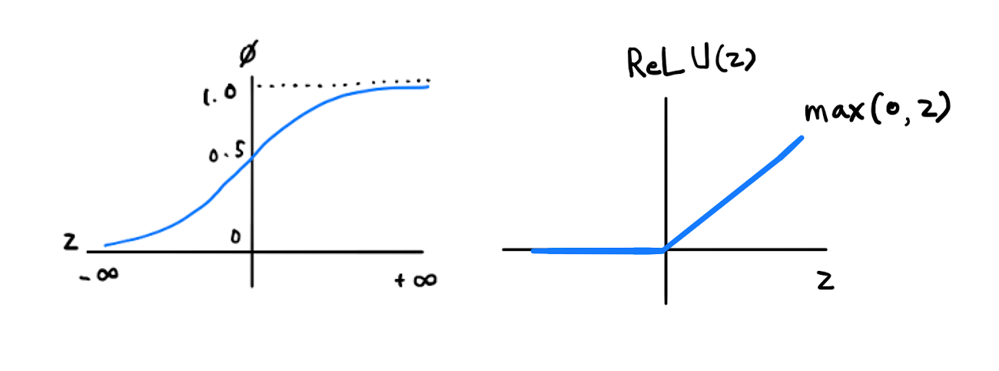

In [ ]:
model = keras.Sequential()
model.add(keras.layers.Flatten(input_shape=(28, 28))) # 입력층 바로 뒤에 플래튼 층 추가
# 플래튼 클래스에 포함된 파라미터는 0개로 케라스의 플래튼 층을 신경만 모델에 추가하면
# 입력값의 차원을 짐작할 수 있는 것이 장점이 됨

# (None, 784) -> 784개의 입력이 첫 번째 은닉층에 전달됨을 알 수 있다.
model.add(keras.layers.Dense(100, activation='relu')) # 렐루층 : true / false를 1단계에서 검사
model.add(keras.layers.Dense(10, activation='softmax')) # 소프트 맥스층 : 다중분류
model.summary() # 여기까지가 딥러닝 모델 생성 끝

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 훈련 데이터를 준비해서 모델 훈련 시작
# reshape() 메서드 제외함. -> 2차원 해상도값을 그대로 사용해 봄
(train_input, train_target), (test_input, test_target) = keras.datasets.fashion_mnist.load_data()

train_scaled = train_input / 255.0

train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

In [ ]:
print(test_input.shape, test_target.shape) # 플래튼을 사용하려고 픽셀값 조정 안함

(10000, 28, 28) (10000,)


In [ ]:
print(train_scaled.shape, train_target.shape) # 플래튼을 사용하려고 픽셀값 조정 안함

(48000, 28, 28) (48000,)


In [ ]:
print(val_scaled.shape, val_target.shape) # 플래튼을 사용하려고 픽셀값 조정 안함

(12000, 28, 28) (12000,)


In [ ]:
# 순차적인 모델을 생성한 후에 컴파일을 통해서 빠른 처리를 위함
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 훈련 시작!!! 에포크 5번 반복
model.fit(train_scaled, train_target, epochs=5)
# 전 시그모이드 정확도(87.81%)와 손실율(33.52%) 비교해보면 조금 향상됨 39초 걸림
# 1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8781 - loss: 0.3352

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8113 - loss: 0.5291
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8580 - loss: 0.3914
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8731 - loss: 0.3525
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8829 - loss: 0.3286
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8892 - loss: 0.3133


In [ ]:
# 옵티마이져 : 최적화

# 하이퍼파라미터는 모델이 학습하지 않아 사람이 지정해 주어야 하는 파라미터
# 신경망에는 특히 하이퍼파라미터가 많다.
# 전에는 하나의 은닉층을 추가하였지만 여러 개의 은닉층을 추가할 수도 있다.
# 추가할 은닉층의 개수는 모델이 학습하는 것이 아니라 우리가 지정해 주어야할 하이퍼파라미터임.
# 은닉 층의 뉴런 개수도 우리가 지정하는 것이 하이퍼 파라미터임. (활성화 함수, 층의 종류 포함)

# 케라스는 기본적으로 미니배치 경사 하강법을 사용하며 미니배치 개수는 32개라고 했다.
# 이를 조정하는 batch_size로 하이퍼 파라미터
# fit() 메서드의 epochs(에포크 : 중요한 사건시점) 매개변수도 하이퍼파라미터임.
#   -> 반복한 횟수에 따라 다른 모델이 만들어짐.

# 마지막으로 compile() 메서드에서는 케라스의 기본 경사 하강법 알고리즘인
#   RMSprop(Root Mean Sqaure Propagation의 약자로, 알엠에스프롭(R.M.S.Prop)이라고 읽습니다.)
# 케라스는 다양한 종류의 경사 하강법을 제공하는데 이를 옵티마이저(optimizer:최적화)라고 부름
#   -> 학습률 또한 조정할 하이퍼파라미터임.

In [ ]:
# 처음부터 모델을 구성하고 각종 하이퍼파라미터의 최적값을 찾는 것은 어려운 작업임.

# 옵티마이저 테스트1 -> 확률적 경사 하강법 SGD
#   (1개의 샘플을 뽑아 훈련하지 않고 앞서 언급한 것 처럼 기본적인 미니 배치를 사용)
model_sgd = keras.Sequential()
model_sgd.add(keras.layers.Flatten(input_shape=(28, 28))) # 입력층 바로 뒤에 플래튼 층 추가
# 플래튼 클래스에 포함된 파라미터는 0개로 케라스의 플래튼 층을 신경만 모델에 추가하면
# 입력값의 차원을 짐작할 수 있는 것이 장점이 됨

# (None, 784) -> 784개의 입력이 첫 번째 은닉층에 전달됨을 알 수 있다.
model_sgd.add(keras.layers.Dense(100, activation='relu')) # 렐루층 : true / false를 1단계에서 검사
model_sgd.add(keras.layers.Dense(10, activation='softmax')) # 소프트 맥스층 : 다중분류
model_sgd.summary() # 여기까지가 딥러닝 모델 생성 끝

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
sgd = keras.optimizers.SGD()    # SGD최적화 객체를 생성하여 변수로 넣는 방법
model_sgd.compile(optimizer=sgd, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# optimizer='sgd' 자동으로 클래스를 객체로 만들고 시작함  sgd = keras.optimizers.SGD() 생략 가능
model_sgd.compile(optimizer='sgd', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_sgd.fit(train_scaled, train_target, epochs=5)
# 최적화 미사용 점수 : 1500/1500 ━━━━ 5s 3ms/step - accuracy: 0.8892 - loss: 0.3133

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7433 - loss: 0.7893
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8173 - loss: 0.5425
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8310 - loss: 0.4925
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8391 - loss: 0.4654
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8446 - loss: 0.4471


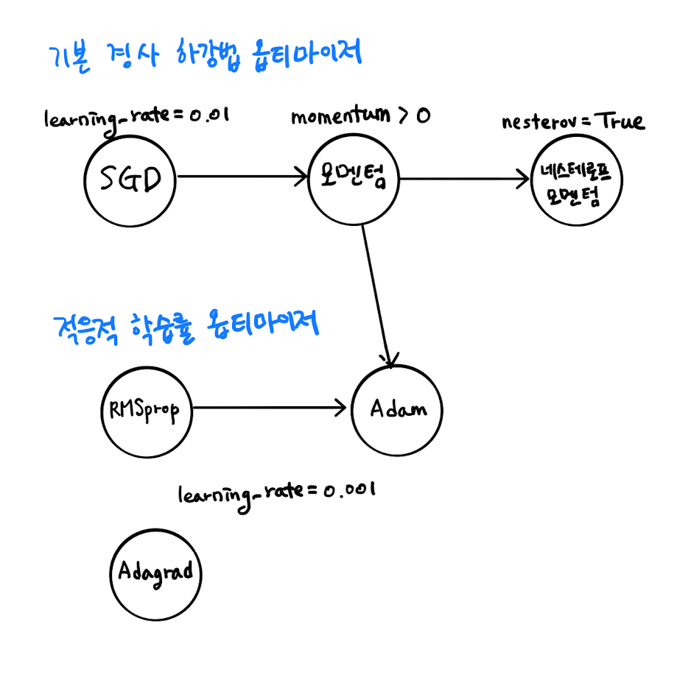

In [ ]:
# 1. 기본 경사 하강법 옵티마이저 (Upper Branch)
# 가장 원초적인 경사 하강법에서 관성(Momentum) 개념과 예측 계산을 추가하며 발전한 형태입니다.

# SGD (Stochastic Gradient Descent, 확률적 경사 하강법)
# 가장 기본이 되는 최적화 알고리즘입니다. 기본 학습률(learning-rate)은 0.01을 주로 사용합니다.

# 모멘텀 (Momentum)
# SGD에 관성(가속도) 개념을 더한 것입니다. 관성 계수(momentum > 0, 보통 0.9 이상)를 적용하여
# 이전에 이동했던 방향으로 계속 가려는 힘을 주어, 언덕을 내달리듯 경사를 빠르게 내려가게 돕습니다.

# 네스테로프 모멘텀 (Nesterov Momentum)
# 모멘텀 기법을 한 단계 더 개선한 방식(nesterov=True)입니다.
# 현재 위치에서 관성 방향으로 일단 이동해 본 뒤 그 위치의 기울기를 계산하므로,
# 일반 모멘텀보다 진행 방향을 더 똑똑하고 안정적으로 조절합니다.

In [ ]:
model_sgd_momentum = keras.Sequential()
model_sgd_momentum.add(keras.layers.Flatten(input_shape=(28, 28))) # 입력층 바로 뒤에 플래튼 층 추가
# 플래튼 클래스에 포함된 파라미터는 0개로 케라스의 플래튼 층을 신경만 모델에 추가하면
# 입력값의 차원을 짐작할 수 있는 것이 장점이 됨

# (None, 784) -> 784개의 입력이 첫 번째 은닉층에 전달됨을 알 수 있다.
model_sgd_momentum.add(keras.layers.Dense(100, activation='relu')) # 렐루층 : true / false를 1단계에서 검사
model_sgd_momentum.add(keras.layers.Dense(10, activation='softmax')) # 소프트 맥스층 : 다중분류
model_sgd_momentum.summary() # 여기까지가 딥러닝 모델 생성 끝

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
sgd = keras.optimizers.SGD(learning_rate=0.1) # learning_rate=0.1원하는 학습율 기록(기본값 0.01)

# 아래 그림처럼 다양한 최적화 기법이 존재 한다.
sgd = keras.optimizers.SGD(momentum=0.9, nesterov=True)
# 모멘텀(기본0 : 그레이디언트 가속도 0.9이상 사용)
# 네스테로프 모멘텀(네스테로프 모멘텀 최적화 = 가속경사)
# 네스테로프 모멘텀은 모멘텀 최적화를 2번 반복하여 구현한다.
#   -> 기본 확률적 경사 하강법보다 더 나은 성능을 제공

# 모델이 최적점에 가까이 갈수록 학습률을 낮출수도 있다.
#   -> 안정적으로 최적점에 수렴 (적응적 학습률 : adaptive learning rate)
# 학습률 매개변수를 튜닝하는 수고를 줄여줌
model_sgd_momentum.compile(optimizer=sgd, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_sgd_momentum.fit(train_scaled, train_target, epochs=5)
# sgd 기본값 결과 : 1500/1500 ━━ 8s 3ms/step - accuracy: 0.8446 - loss: 0.4471

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8120 - loss: 0.5353
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8545 - loss: 0.4042
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8668 - loss: 0.3664
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8753 - loss: 0.3415
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8821 - loss: 0.3221


In [ ]:
# 2. 적응적 학습률 옵티마이저 (Lower Branch)
# 가중치(파라미터)마다 상황에 맞게 학습률(Learning Rate)을 알아서 다르게 조절(Adaptive)해 주는 알고리즘들입니다.

# Adagrad (에이다그레이드)
# 많이 변화한 파라미터는 학습률을 줄이고, 적게 변화한 파라미터는
# 학습률을 높여 불균일한 데이터/특성에 잘 대처합니다. 기본 학습률은 0.001 수준입니다.

# RMSprop (알엠에스프롭)
# Adagrad가 학습이 진행될수록 학습률이 0에 너무 가까워져
# 결국 학습을 멈추는 단점을 지수 이동 평균 방식을 통해 보완한 알고리즘입니다. (케라스의 기본 옵티마이저 중 하나)

# Adam (아담)
# [모멘텀(관성) + RMSprop(적응적 학습률)]의 장점만을 조합하여 만든
# 현대 딥러닝에서 가장 널리 쓰이는 대표적인 최적화 알고리즘입니다.
# 경사를 내달리는 속도감(모멘텀)과 유연한 보폭 조절(RMSprop)을 동시에 수행합니다.

# 적응적 학습률 : adaptive learning rate을 사용하는 대표적인 최적화기법은 Adagrad, RMSprop가 있다.
# complie()메서드의 optimizer=adagrad, optimizer=rmsprop(기본값)

In [ ]:
model_adagrad = keras.Sequential()  # 딥러닝의 레이어 생성
model_adagrad.add(keras.layers.Flatten(input_shape=(28, 28)))   # 입력층(1차원 변환없이 사용)
model_adagrad.add(keras.layers.Dense(100, activation='relu'))   # 은닉층(렐루)
model_adagrad.add(keras.layers.Dense(10, activation='softmax')) # 출력층(소프트맥스)
model_adagrad.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_adagrad.compile(optimizer='adagrad', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# 적응적 학습률 최적화(에이다그레드)
model_adagrad.fit(train_scaled, train_target, epochs=10)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6345 - loss: 1.1987
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7504 - loss: 0.7778
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7785 - loss: 0.6893
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7935 - loss: 0.6427
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8024 - loss: 0.6126
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8087 - loss: 0.5911
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8131 - loss: 0.5747
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8170 - loss: 0.5616
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8201 - loss: 0.5509
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8224 - loss: 0.5418


In [ ]:
model_adagrad.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8198 - loss: 0.5521


[0.552124559879303, 0.8197500109672546]

In [ ]:
# model.fit()을 여러 번 실행하는 것과 SGDClassifier의 partial_fit()을 여러 번 호출하는 것은
# "기존에 학습된 가중치(파라미터)를 지우지 않고 이어서 업데이트한다"는 점에서 똑같이 작동합니다.

In [ ]:
# RMSprop 테스트 (새 모델로 초기화)
model_rmsprop = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
]) # 케라스3버전용으로 만들어 봄
model_rmsprop.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_rmsprop.fit(train_scaled, train_target, epochs=10)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8100 - loss: 0.5374
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8563 - loss: 0.3957
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8730 - loss: 0.3545
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8822 - loss: 0.3305
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8895 - loss: 0.3134
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8951 - loss: 0.2997
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8995 - loss: 0.2880
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9027 - loss: 0.2803
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9060 - loss: 0.2714
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9082 - loss: 0.2660


In [ ]:
model_rmsprop.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8616 - loss: 0.4392


[0.43920907378196716, 0.8615833520889282]

In [ ]:
# Adam 테스트 (새 모델로 초기화)
model_adam = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])
model_adam.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_adam.fit(train_scaled, train_target, epochs=10)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8182 - loss: 0.5188
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8587 - loss: 0.3915
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8727 - loss: 0.3477
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8827 - loss: 0.3202
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8904 - loss: 0.2993
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8962 - loss: 0.2833
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9011 - loss: 0.2691
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9050 - loss: 0.2571
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9094 - loss: 0.2467
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9124 - loss: 0.2365


In [ ]:
model_adam.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8808 - loss: 0.3416


[0.34163424372673035, 0.8807500004768372]

In [ ]:
test_scaled = test_input / 255.0    # 마지막 평가 점수 분석(스케일조정 필수)

model_adam.evaluate(test_scaled, test_target)
# 예를 들어 테스트 데이터가 10,000개라면 → 약 8,560개 맞춤
# 손실 0.3404은 평균적으로 정답 클래스에 약 69~70% 확신을 가진 상태이며
# 정확도 87%와 일관된 정상적인 Cross Entropy 값이다.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8785 - loss: 0.3404


[0.34040772914886475, 0.8784999847412109]

In [ ]:
model_adam.predict(test_input[0:1])
#0티셔츠, 1바지, 2스웨터, 3드레스, 4코트, 5샌달, 6셔츠, 7스니커즈, 8가방, 9앵클부츠

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

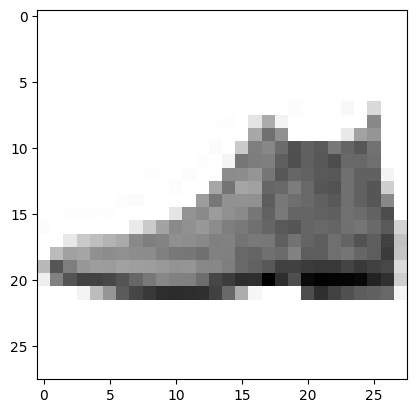

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(test_input[0], cmap='gray_r')
# 첫 번째 샘플인 val_scaled[0]
plt.show()  # 검증용리스트의 0번에 있는 이미지를 출력하였다.